In [2]:
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [3]:
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
train_images = train_images.reshape((60000, 28, 28, 1)).astype("float32") / 255
test_images = test_images.reshape((10000, 28, 28, 1)).astype("float32") / 255

In [5]:
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

In [6]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
history = model.fit(
    train_images, train_labels,
    epochs=10,
    batch_size=64,
    validation_data=(test_images, test_labels)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8003 - loss: 0.5438 - val_accuracy: 0.8339 - val_loss: 0.4422
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8809 - loss: 0.3327 - val_accuracy: 0.8858 - val_loss: 0.3204
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8966 - loss: 0.2840 - val_accuracy: 0.8863 - val_loss: 0.3070
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9064 - loss: 0.2520 - val_accuracy: 0.8979 - val_loss: 0.2927
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9160 - loss: 0.2289 - val_accuracy: 0.9047 - val_loss: 0.2694
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9222 - loss: 0.2104 - val_accuracy: 0.8890 - val_loss: 0.3268
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9279 - loss: 0.1938 - val_accuracy: 0.8916 - val_loss: 0.3164
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9348 - loss: 0.1776 - val_accuracy: 0

In [8]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Точність базової CNN: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9016 - loss: 0.2887
Точність базової CNN: 0.9016


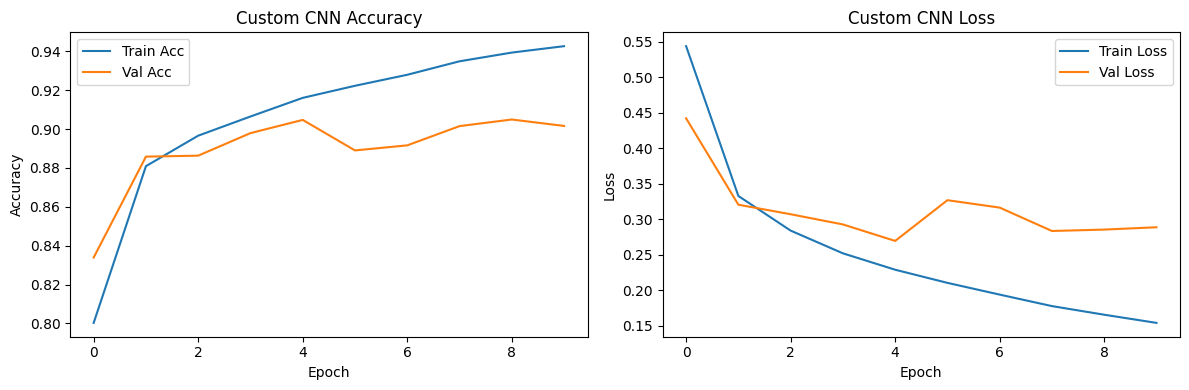

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Custom CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Custom CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('cnn_history.png')
plt.show()

model.save('custom_cnn_model.keras')

VGG16

In [10]:
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras import models, layers
import numpy as np

In [11]:
(train_images_raw, train_labels_raw), (test_images_raw, test_labels_raw) = fashion_mnist.load_data()

In [12]:
train_padded = np.pad(train_images_raw, ((0,0), (2,2), (2,2)), mode='constant')
test_padded = np.pad(test_images_raw, ((0,0), (2,2), (2,2)), mode='constant')

In [13]:
train_images_vgg = np.expand_dims(train_padded, axis=-1)
train_images_vgg = np.repeat(train_images_vgg, 3, axis=-1).astype("float32") / 255

test_images_vgg = np.expand_dims(test_padded, axis=-1)
test_images_vgg = np.repeat(test_images_vgg, 3, axis=-1).astype("float32") / 255

train_labels_vgg = to_categorical(train_labels_raw)
test_labels_vgg = to_categorical(test_labels_raw)

In [14]:
conv_base = VGG16(weights="imagenet", include_top=False, input_shape=(32, 32, 3))
conv_base.trainable = False

model_vgg = models.Sequential([
    conv_base,
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_vgg.compile(
    loss="categorical_crossentropy",
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=2e-5),
    metrics=["accuracy"]
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [15]:
print("Навчання класифікатора (заморожена база)")
model_vgg.fit(
    train_images_vgg, train_labels_vgg,
    epochs=5,
    batch_size=64,
    validation_data=(test_images_vgg, test_labels_vgg)
)

Навчання класифікатора (заморожена база)
Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - accuracy: 0.3558 - loss: 1.9356 - val_accuracy: 0.6386 - val_loss: 1.3824
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.6018 - loss: 1.2815 - val_accuracy: 0.7072 - val_loss: 0.9754
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.6628 - loss: 1.0278 - val_accuracy: 0.7300 - val_loss: 0.8303
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.6890 - loss: 0.9156 - val_accuracy: 0.7437 - val_loss: 0.7617
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.7060 - loss: 0.8568 - val_accuracy: 0.7530 - val_loss: 0.7221


In [16]:
conv_base.trainable = True

set_trainable = False
for layer in conv_base.layers:
    if layer.name == "block5_conv1":
        set_trainable = True
    if set_trainable:
        layer.trainable = True
    else:
        layer.trainable = False

In [17]:
model_vgg.compile(
    loss="categorical_crossentropy",
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=1e-5),
    metrics=["accuracy"]
)

In [18]:
print("Донавчання (Fine-Tuning)")
history_vgg = model_vgg.fit(
    train_images_vgg, train_labels_vgg,
    epochs=10,
    batch_size=64,
    validation_data=(test_images_vgg, test_labels_vgg)
)

Донавчання (Fine-Tuning)
Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.8185 - loss: 0.5020 - val_accuracy: 0.8521 - val_loss: 0.4113
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8640 - loss: 0.3752 - val_accuracy: 0.8754 - val_loss: 0.3511
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8806 - loss: 0.3334 - val_accuracy: 0.8863 - val_loss: 0.3199
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8884 - loss: 0.3062 - val_accuracy: 0.8909 - val_loss: 0.3095
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8963 - loss: 0.2874 - val_accuracy: 0.8972 - val_loss: 0.2971
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.9015 - loss: 0.2716 - val_accuracy: 0.8995 - val_loss: 0.2861
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.9056 - loss: 0.2597 - val_accuracy: 0.9006 - val_loss: 0.2848
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy:

In [19]:
test_loss_vgg, test_acc_vgg = model_vgg.evaluate(test_images_vgg, test_labels_vgg)
print(f"Точність VGG16 (Fine-Tuning): {test_acc_vgg:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9031 - loss: 0.2736
Точність VGG16 (Fine-Tuning): 0.9031


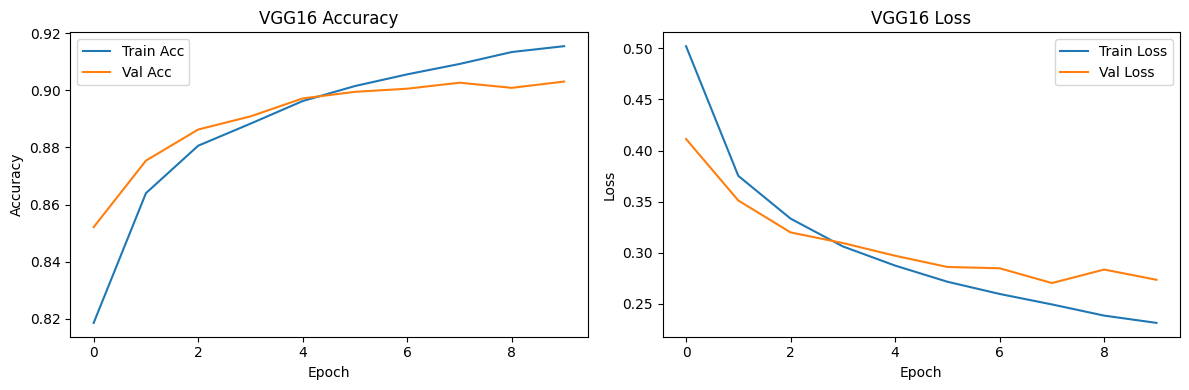

In [20]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_vgg.history['accuracy'], label='Train Acc')
plt.plot(history_vgg.history['val_accuracy'], label='Val Acc')
plt.title('VGG16 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_vgg.history['loss'], label='Train Loss')
plt.plot(history_vgg.history['val_loss'], label='Val Loss')
plt.title('VGG16 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('vgg16_history.png')
plt.show()

model_vgg.save('vgg16_model.keras')